# Loan Approval Prediction

**Goal:** predict whether a bank will **approve or reject** a loan application, using the applicant's details such as income, credit (CIBIL) score, assets and loan size.

This is a **classification** problem: we predict a category (Approved / Rejected), not a number.

**Models compared:** Logistic Regression, Decision Tree, Random Forest (plus a "lazy" baseline that approves everyone).

**How to use this notebook**

1. Save your data as `dataset/loan_data.csv` inside the project folder.
2. Run the cells from top to bottom (**Kernel → Restart & Run All**).
3. Charts appear in the notebook and are also saved to `results/visualizations/`.

**Contents**

| Part | Section |
|---|---|
| 0 | Setup: libraries, settings and helper functions |
| 1 | Load the dataset |
| 2 | Explore the data |
| 3 | Clean the data |
| 4 | Visualize the data |
| 5 | Prepare the data for the models |
| 6 | Find the most important features |
| 7 | Train the models |
| 8 | Evaluate the models |
| 9 | Compare the models and pick the best |
| 10 | Final report |

## 0. Setup

### 0.1 Import the libraries
Libraries are ready-made toolboxes. Here is what each one does for us:

- **pandas / numpy**: handle tables and numbers
- **matplotlib / seaborn**: draw charts
- **scikit-learn**: the machine learning tools (models, scores, data splitting)
- **joblib**: saves the trained model to a file

In [7]:
import os
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
print("Libraries loaded.")

Libraries loaded.


### 0.2 Settings
- The notebook finds the project folder by itself, whether it sits in the project folder or inside `notebooks/`.
- `RANDOM_STATE = 42` makes the results the same every time you run the notebook.
- We list which columns are **text categories** (`CAT_COLS`) and which are **numbers** (`NUM_COLS`). Two number columns, `total_assets` and `loan_to_income`, are built later.

In [8]:
# Find the project folder (works from the project folder or from notebooks/)
ROOT = "." if os.path.exists("dataset/loan_data.csv") else ".."
DATA_PATH = os.path.join(ROOT, "dataset", "loan_data.csv")
RESULTS_DIR = os.path.join(ROOT, "results")
VIS_DIR = os.path.join(RESULTS_DIR, "visualizations")
os.makedirs(VIS_DIR, exist_ok=True)

RANDOM_STATE = 42

CAT_COLS = ["education", "self_employed"]
ASSET_COLS = [
    "residential_assets_value",
    "commercial_assets_value",
    "luxury_assets_value",
    "bank_asset_value",
]
NUM_COLS = [
    "no_of_dependents",
    "income_annum",
    "loan_amount",
    "loan_term",
    "cibil_score",
] + ASSET_COLS + ["total_assets", "loan_to_income"]

REQUIRED_RAW_COLS = [
    "no_of_dependents", "education", "self_employed", "income_annum", "loan_amount",
    "loan_term", "cibil_score", "residential_assets_value", "commercial_assets_value",
    "luxury_assets_value", "bank_asset_value", "loan_status",
]

print("Project folder:", os.path.abspath(ROOT))

Project folder: c:\Users\gauth\OneDrive\Desktop


### 0.3 Helper functions
Small reusable tools we will call later.

- `save_plot`: shows a chart here and saves a copy to `results/visualizations/`.
- `engineer_features`: builds the exact columns the model needs. It is used for the training data and for any new applicant.
  - `total_assets` = all four asset values added together
  - `loan_to_income` = how many years of income the loan equals (a bigger number means a riskier loan)
- `make_preprocessor`: fills any missing values and converts columns into numbers the models understand. It is placed **inside** each model's pipeline, so fill-in values are learned from the training data only and the test data stays truly unseen.
- `make_model`: glues the preprocessing and a classifier into one pipeline.

In [9]:
def save_plot(filename):
    """Show the current chart and save a copy to results/visualizations."""
    plt.tight_layout()
    plt.savefig(os.path.join(VIS_DIR, filename), dpi=120)
    plt.show()


def engineer_features(data):
    """Build the model's input columns from the raw applicant details."""
    out = data.copy()
    out["total_assets"] = out[ASSET_COLS].sum(axis=1)
    out["loan_to_income"] = out["loan_amount"] / out["income_annum"]
    return out[CAT_COLS + NUM_COLS]


def make_preprocessor():
    """
    numbers : fill missing with the median, then scale to a similar range
    text    : fill missing with the most common value, then one-hot encode
              (e.g. education -> 0/1 columns)
    """
    numeric_pipe = Pipeline(
        [("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]
    )
    categorical_pipe = Pipeline(
        [
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]
    )
    return ColumnTransformer(
        [("num", numeric_pipe, NUM_COLS), ("cat", categorical_pipe, CAT_COLS)]
    )


def make_model(classifier):
    """Preprocessing + classifier glued together as one pipeline."""
    return Pipeline([("prep", make_preprocessor()), ("model", classifier)])


print("Helper functions ready.")

Helper functions ready.


---
## 1. Load the Dataset

We read `dataset/loan_data.csv` into a table (a pandas **DataFrame**) called `df`.

This file has stray spaces in its column names and text values (for example `" education"` and `" Graduate"`), so we also trim them right away. Otherwise a name like `"education"` would not match `" education"`.

In [10]:
if not os.path.exists(r"C:\Users\gauth\OneDrive\Desktop\Classification_Loan\loan.csv"):
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Save your loan data as dataset/loan_data.csv and run again."
    )

df = pd.read_csv(r"C:\Users\gauth\OneDrive\Desktop\Classification_Loan\loan.csv")

# Remove extra spaces from column names and text values
df.columns = df.columns.str.strip()
for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].str.strip()

print("Dataset loaded.")

Dataset loaded.


---
## 2. Explore the Data

Before changing anything, we look at what we have: how big the table is, what the columns are, and how many loans were approved or rejected.

### 2.1 Size and first rows

In [11]:
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (4269, 13)


,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


### 2.2 Column types and summary numbers
`describe()` shows the smallest, largest and average value of each number column. Look for strange values here, such as a negative asset value.

In [12]:
print(df.dtypes)
df.describe().round(2)

loan_id                      int64
no_of_dependents             int64
education                   object
self_employed               object
income_annum                 int64
loan_amount                  int64
loan_term                    int64
cibil_score                  int64
residential_assets_value     int64
commercial_assets_value      int64
luxury_assets_value          int64
bank_asset_value             int64
loan_status                 object
dtype: object


,loan_id,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
count,4269.0,4269.0,4269.00,4269.00,4269.00,4269.00,4269.00,4269.00,4269.00,4269.00
mean,2135.0,2.5,5059123.92,15133450.46,10.90,599.94,7472616.54,4973155.31,15126305.93,4976692.43
std,1232.5,1.7,2806839.83,9043362.98,5.71,172.43,6503636.59,4388966.09,9103753.67,3250185.31
min,1.0,0.0,200000.00,300000.00,2.00,300.00,-100000.00,0.00,300000.00,0.00
25%,1068.0,1.0,2700000.00,7700000.00,6.00,453.00,2200000.00,1300000.00,7500000.00,2300000.00
50%,2135.0,3.0,5100000.00,14500000.00,10.00,600.00,5600000.00,3700000.00,14600000.00,4600000.00
75%,3202.0,4.0,7500000.00,21500000.00,16.00,748.00,11300000.00,7600000.00,21700000.00,7100000.00
max,4269.0,5.0,9900000.00,39500000.00,20.00,900.00,29100000.00,19400000.00,39200000.00,14700000.00


### 2.3 Approved vs rejected
This is the answer we want the model to predict (the **target**). Everything else is a **feature**, meaning an input the model learns from.

In [13]:
df["loan_status"].value_counts()

Approved    2656
Rejected    1613
Name: loan_status, dtype: int64

---
## 3. Clean the Data

We fix problems that would confuse the models.

### 3.1 Missing values
We check every column for empty cells. This dataset has none, but we always check. If there were any, the pipeline would fill them later using training data only.

In [14]:
missing = df.isnull().sum()
print(missing[missing > 0] if missing.any() else "No missing values.")

No missing values.


### 3.2 Drop useless columns and duplicate rows
- `loan_id` is only a label. It says nothing about whether a loan should be approved, so we drop it.
- Duplicate rows would count the same application twice, so we remove them.

In [15]:
if "loan_id" in df.columns:
    df = df.drop(columns=["loan_id"])

dupes = df.duplicated().sum()
print(f"Duplicate rows found: {dupes}")
df = df.drop_duplicates()

Duplicate rows found: 0


### 3.3 Remove impossible values
An asset cannot be worth less than 0. A few rows break that rule, so they are data errors and we remove them.

In [16]:
bad_assets = (df[ASSET_COLS] < 0).any(axis=1).sum()
print(f"Rows with a negative asset value (impossible): {bad_assets}")
df = df[(df[ASSET_COLS] >= 0).all(axis=1)]

Rows with a negative asset value (impossible): 28


### 3.4 Turn the answer into numbers
Models work with numbers, so **Approved becomes 1** and **Rejected becomes 0**. We store this in a new column called `Approved`.

In [17]:
df["Approved"] = (df["loan_status"] == "Approved").astype(int)
df = df.drop(columns=["loan_status"])
df = df.reset_index(drop=True)

print("Clean dataset shape:", df.shape)

Clean dataset shape: (4241, 12)


### 3.5 The "lazy" baseline
What if the bank simply approved **everyone**? That gives us a score every real model has to beat. If most loans are approved, this lazy approach already looks good on accuracy, which is why we will also use other scores later.

In [18]:
baseline_acc = df["Approved"].mean()
print(f"Approving EVERYONE would be right {baseline_acc * 100:.1f}% of the time.")

Approving EVERYONE would be right 62.2% of the time.


---
## 4. Visualize the Data

Charts help us see patterns before we build any model. Each chart is also saved in `results/visualizations/`.

### 4.1 Approved vs rejected
How many loans fall in each group?

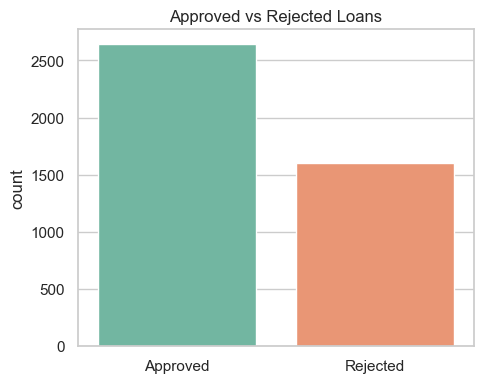

In [19]:
decision = df["Approved"].map({1: "Approved", 0: "Rejected"})

plt.figure(figsize=(5, 4))
sns.countplot(x=decision, palette="Set2")
plt.title("Approved vs Rejected Loans")
plt.xlabel("")
save_plot("01_approval_counts.png")

### 4.2 CIBIL (credit) score by decision
**What to look for:** do approved and rejected loans sit in different score ranges? A clear split means the score is a strong signal.

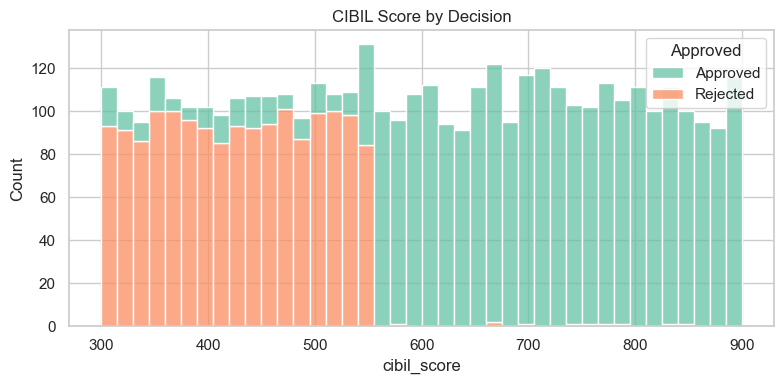

In [20]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="cibil_score", hue=decision, bins=40, multiple="stack", palette="Set2")
plt.title("CIBIL Score by Decision")
save_plot("02_cibil_score_by_decision.png")

### 4.3 Approval rate by CIBIL score band
The same idea as before, but as the **percentage approved** inside each score band. Notice where the rate jumps.

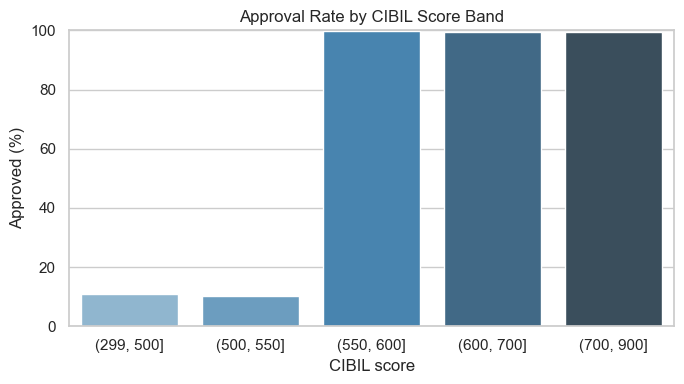

In [21]:
bands = pd.cut(df["cibil_score"], [299, 500, 550, 600, 700, 900])
rate = df.groupby(bands, observed=True)["Approved"].mean() * 100

plt.figure(figsize=(7, 4))
sns.barplot(x=rate.index.astype(str), y=rate.values, palette="Blues_d")
plt.title("Approval Rate by CIBIL Score Band")
plt.ylabel("Approved (%)")
plt.xlabel("CIBIL score")
plt.ylim(0, 100)
save_plot("03_approval_by_cibil_band.png")

### 4.4 Approval rate by other details
Education, self-employment, number of dependents and loan term. If a bar is much higher or lower than the others, that detail may matter.

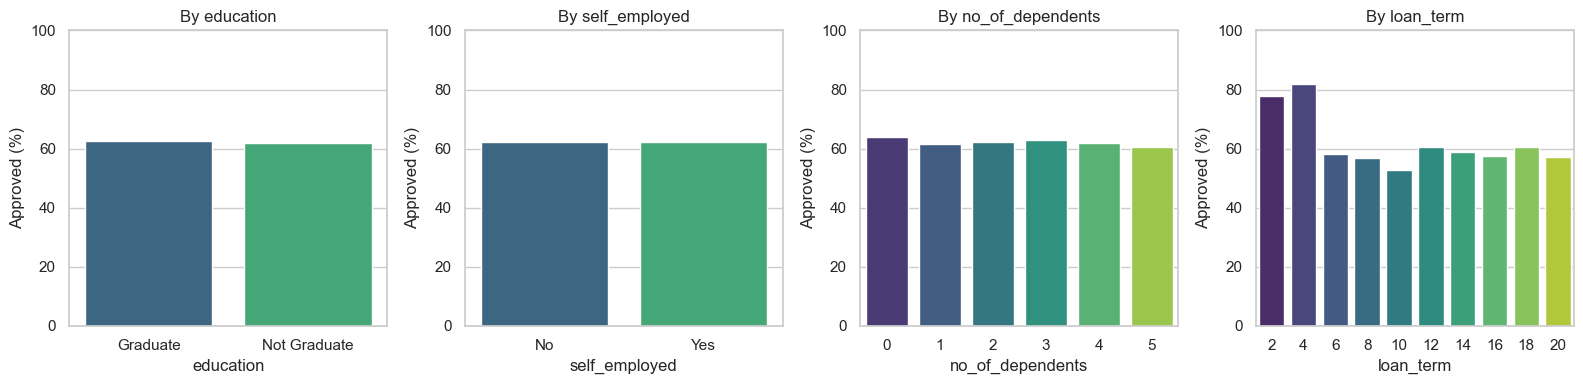

In [22]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, ["education", "self_employed", "no_of_dependents", "loan_term"]):
    r = df.groupby(col)["Approved"].mean() * 100
    sns.barplot(x=r.index, y=r.values, ax=ax, palette="viridis")
    ax.set_title(f"By {col}")
    ax.set_ylabel("Approved (%)")
    ax.set_ylim(0, 100)
save_plot("04_approval_by_other_features.png")

### 4.5 Income and loan amount by decision
Box plots show the typical range (the box) and the extremes (the dots). Do approved applicants earn more, or ask for less?

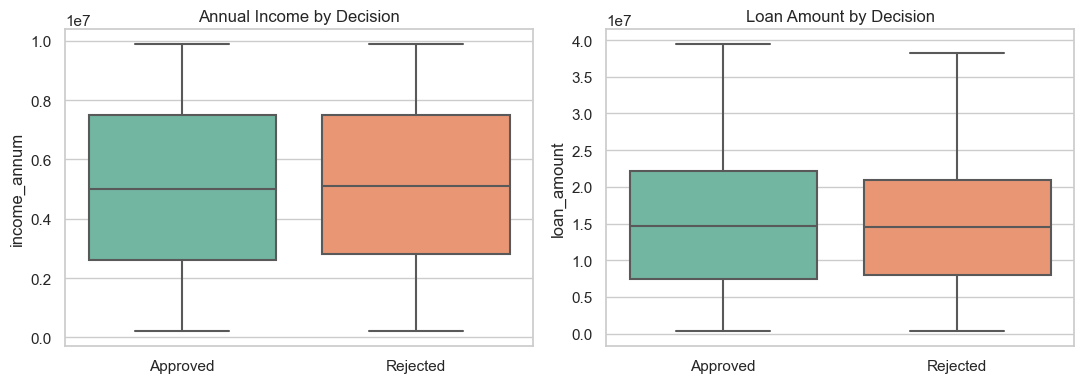

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(x=decision, y=df["income_annum"], ax=axes[0], palette="Set2")
axes[0].set_title("Annual Income by Decision")
axes[0].set_xlabel("")
sns.boxplot(x=decision, y=df["loan_amount"], ax=axes[1], palette="Set2")
axes[1].set_title("Loan Amount by Decision")
axes[1].set_xlabel("")
save_plot("05_income_and_loan_by_decision.png")

### 4.6 Correlation heatmap
Shows how strongly the number columns move together. Values near **+1 or -1** mean a strong link, values near **0** mean almost none. Look at the last row (`Approved`) to see which columns relate most to the decision.

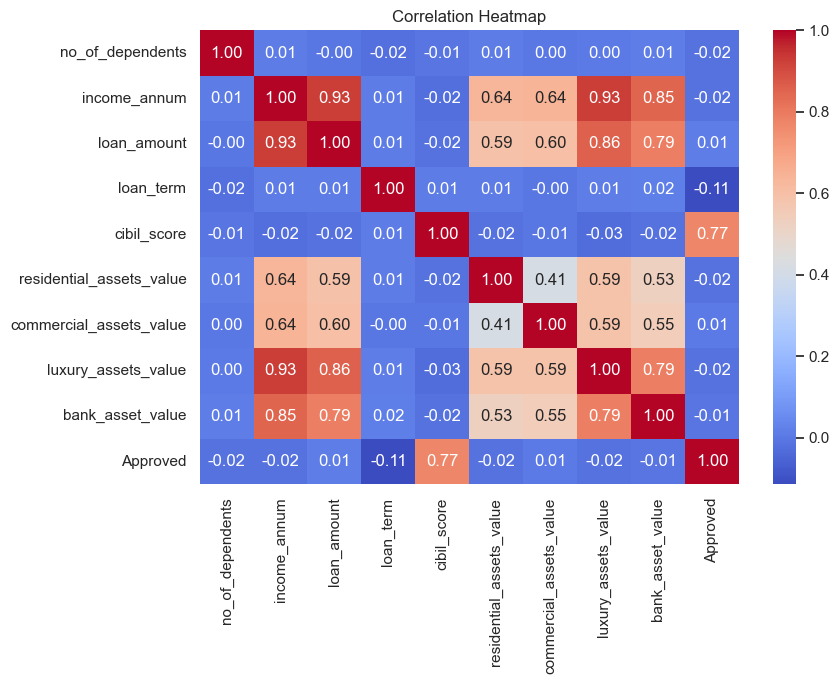

In [24]:
plt.figure(figsize=(9, 7))
sns.heatmap(df[NUM_COLS[:9] + ["Approved"]].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
save_plot("06_correlation_heatmap.png")

---
## 5. Prepare the Data for the Models

### 5.1 Build inputs (X) and the answer (y)
- **X** = the details the model can look at
- **y** = what we want it to predict (approved or not)

In [25]:
X = engineer_features(df)
y = df["Approved"]

print("Columns the model will use:")
print(list(X.columns))

Columns the model will use:
['education', 'self_employed', 'no_of_dependents', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value', 'total_assets', 'loan_to_income']


### 5.2 Split into training and testing data
- **80% training:** the models learn from these loans.
- **20% testing:** kept hidden until the end, to check how the models do on loans they have **never seen**.

`stratify=y` keeps the same approved/rejected ratio in both parts, so the test is fair.

In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print(f"Training rows: {len(X_train)} | Testing rows: {len(X_test)}")

Training rows: 3392 | Testing rows: 849


---
## 6. Find the Most Important Features

A quick Random Forest tells us how useful each column was for the decision. A higher bar means the column influenced approval more.

(A name such as `education_Graduate` means the 0/1 column made from the education text.)

Top 10 features:
cibil_score                 0.805
loan_term                   0.075
loan_to_income              0.044
loan_amount                 0.015
total_assets                0.010
luxury_assets_value         0.010
bank_asset_value            0.010
commercial_assets_value     0.009
residential_assets_value    0.008
income_annum                0.008
dtype: float64


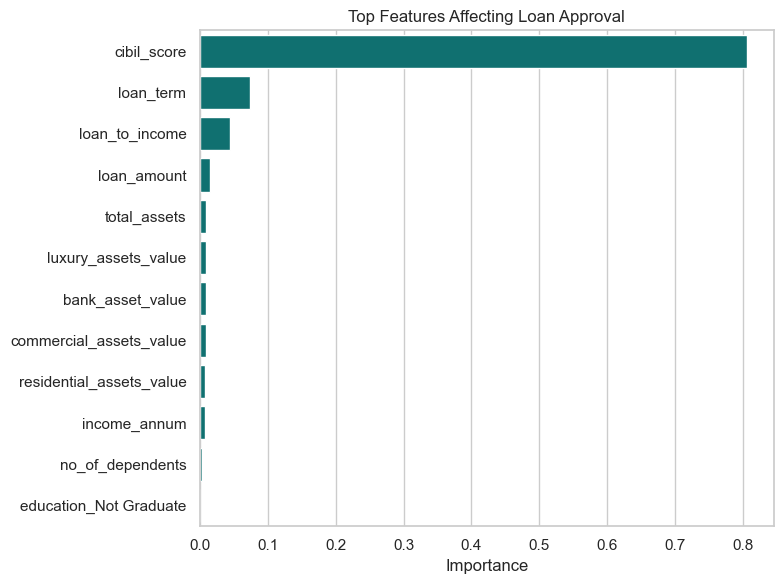

In [27]:
prep = make_preprocessor()
X_train_ready = prep.fit_transform(X_train)
feature_names = [name.split("__", 1)[1] for name in prep.get_feature_names_out()]

quick_forest = RandomForestClassifier(
    n_estimators=200, max_depth=6, random_state=RANDOM_STATE, n_jobs=-1
)
quick_forest.fit(X_train_ready, y_train)

importance = pd.Series(quick_forest.feature_importances_, index=feature_names).sort_values(
    ascending=False
)
print("Top 10 features:")
print(importance.head(10).round(3))

plt.figure(figsize=(8, 6))
sns.barplot(x=importance.head(12).values, y=importance.head(12).index, color="teal")
plt.title("Top Features Affecting Loan Approval")
plt.xlabel("Importance")
save_plot("08_feature_importance.png")

**Decision:** we keep **all** features, because there are only a few and each adds some information.

**Note for your conclusions:** if one feature dominates (check the chart above), the models will mostly learn that single rule.

---
## 7. Train the Models

We train four models. All of them sit inside a pipeline, so each one gets the same cleaning and conversion steps.

| Model | Idea |
|---|---|
| **Baseline** | Always says "approved". The score to beat. |
| **Logistic Regression** | Simple model that weighs each detail and estimates the chance of approval. |
| **Decision Tree** | Asks a series of yes/no questions, like a flowchart. |
| **Random Forest** | Many decision trees vote together, which is steadier than one tree. |

`class_weight="balanced"` tells the models to pay extra attention to the smaller group (rejected loans). `max_depth` limits how complex a tree can get, which helps avoid memorizing the training data (**overfitting**).

In [28]:
models = {
    "Baseline (always approve)": make_model(DummyClassifier(strategy="most_frequent")),
    "Logistic Regression": make_model(
        LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)
    ),
    "Decision Tree": make_model(
        DecisionTreeClassifier(
            max_depth=4, min_samples_leaf=10, class_weight="balanced", random_state=RANDOM_STATE
        )
    ),
    "Random Forest": make_model(
        RandomForestClassifier(
            n_estimators=300,
            max_depth=6,
            min_samples_leaf=5,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )
    ),
}

for name, model in models.items():
    model.fit(X_train, y_train)  # the model learns patterns here
    print(f"Trained: {name}")

Trained: Baseline (always approve)
Trained: Logistic Regression
Trained: Decision Tree
Trained: Random Forest


---
## 8. Evaluate the Models

Now we test every model on the 20% of loans it has never seen.

**How to read the scores**

| Score | Plain meaning |
|---|---|
| **Accuracy** | Share of all predictions that were correct. |
| **Precision** | Of the loans the model approved, how many deserved approval. |
| **Recall** | Of the loans that deserved approval, how many the model found. |
| **F1** | One number balancing precision and recall. |
| **Macro F1** | F1 averaged over Approved **and** Rejected, so a model cannot win just by approving almost everyone. |
| **Reject recall** | Of the loans that should be rejected, how many the model caught. |
| **ROC AUC** | How well the model separates the two groups (0.5 = guessing, 1.0 = perfect). |
| **CV F1** | F1 from 5-fold cross-validation on the training data, which shows if the result is stable and not just lucky. |
| **Overfit gap** | Training accuracy minus test accuracy. A large positive gap means the model memorized the training data. |

In [29]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

results = []
predictions = {}

for name, model in models.items():
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    predictions[name] = pred

    train_acc = accuracy_score(y_train, model.predict(X_train))
    test_acc = accuracy_score(y_test, pred)
    cv_f1 = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1").mean()

    results.append(
        {
            "Model": name,
            "Accuracy": test_acc,
            "Precision": precision_score(y_test, pred, zero_division=0),
            "Recall": recall_score(y_test, pred, zero_division=0),
            "F1": f1_score(y_test, pred, zero_division=0),
            "Macro_F1": f1_score(y_test, pred, average="macro", zero_division=0),
            "Reject_Recall": recall_score(y_test, pred, pos_label=0, zero_division=0),
            "ROC_AUC": roc_auc_score(y_test, proba),
            "CV_F1": cv_f1,
            "Train_Accuracy": train_acc,
            "Overfit_Gap": train_acc - test_acc,
        }
    )

print("Evaluation finished.")

Evaluation finished.


---
## 9. Compare the Models and Pick the Best

### 9.1 Comparison table
Sorted by **Macro F1**, the fairest single score here. The table is also saved as `results/model_comparison.csv`.

In [30]:
comparison = pd.DataFrame(results).round(4)
comparison = comparison.sort_values("Macro_F1", ascending=False).reset_index(drop=True)
comparison.to_csv(os.path.join(RESULTS_DIR, "model_comparison.csv"), index=False)
comparison

,Model,Accuracy,Precision,Recall,F1,Macro_F1,Reject_Recall,ROC_AUC,CV_F1,Train_Accuracy,Overfit_Gap
0,Decision Tree,0.9953,0.9925,1.0000,0.9962,0.9950,0.9875,0.9968,0.9969,0.9973,0.0021
1,Random Forest,0.9953,0.9925,1.0000,0.9962,0.9950,0.9875,0.9993,0.9972,0.9973,0.0021
2,Logistic Regression,0.9317,0.9485,0.9413,0.9449,0.9275,0.9159,0.9784,0.9291,0.9189,-0.0128
3,Baseline (always approve),0.6219,0.6219,1.0000,0.7669,0.3834,0.0000,0.5000,0.7674,0.6226,0.0007


### 9.2 Scores side by side

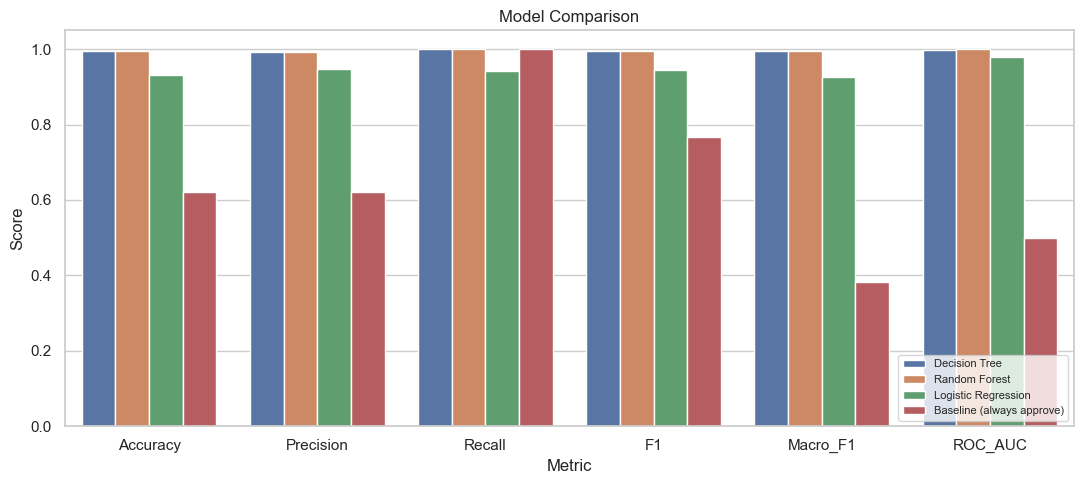

In [31]:
metric_cols = ["Accuracy", "Precision", "Recall", "F1", "Macro_F1", "ROC_AUC"]
melted = comparison.melt(id_vars="Model", value_vars=metric_cols, var_name="Metric", value_name="Score")

plt.figure(figsize=(11, 5))
sns.barplot(data=melted, x="Metric", y="Score", hue="Model")
plt.ylim(0, 1.05)
plt.title("Model Comparison")
plt.legend(loc="lower right", fontsize=8)
save_plot("09_model_comparison.png")

### 9.3 Pick the best model
The best model is the one with the highest **Macro F1** among the real models (the baseline is not allowed to win).

In [32]:
real = comparison[~comparison["Model"].str.startswith("Baseline")].reset_index(drop=True)
best_name = real.loc[0, "Model"]
best_model = models[best_name]
best = real.iloc[0]

print(f"BEST MODEL: {best_name}")
print(f"Macro F1 = {best['Macro_F1']:.3f} | Accuracy = {best['Accuracy']:.3f}")

BEST MODEL: Decision Tree
Macro F1 = 0.995 | Accuracy = 0.995


### 9.4 Confusion matrix of the best model
A small table of right and wrong predictions:

- **Diagonal boxes (top-left, bottom-right):** correct predictions.
- **Off-diagonal boxes:** mistakes. One kind is a bad loan that was approved, the other is a good loan that was rejected.

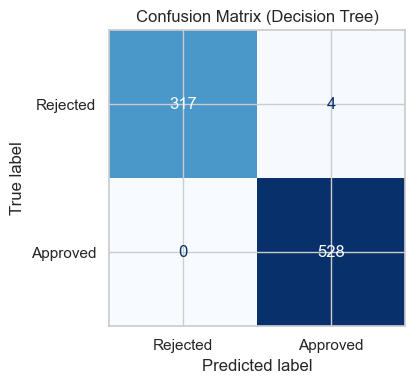

In [33]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions[best_name],
    display_labels=["Rejected", "Approved"],
    ax=ax,
    cmap="Blues",
    colorbar=False,
)
ax.set_title(f"Confusion Matrix ({best_name})")
save_plot("10_confusion_matrix.png")

### 9.5 Detailed report for the best model
Precision, recall and F1 shown separately for Rejected and Approved loans.

In [34]:
print(
    classification_report(
        y_test, predictions[best_name], target_names=["Rejected", "Approved"], zero_division=0
    )
)

              precision    recall  f1-score   support

    Rejected       1.00      0.99      0.99       321
    Approved       0.99      1.00      1.00       528

    accuracy                           1.00       849
   macro avg       1.00      0.99      0.99       849
weighted avg       1.00      1.00      1.00       849



### 9.6 ROC curves
Each line shows how well a model separates approved from rejected loans. **The closer a line hugs the top-left corner, the better.** The dashed line is pure guessing.

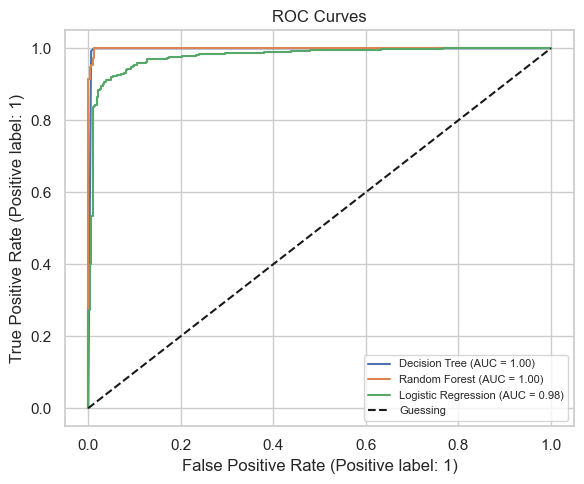

In [35]:
fig, ax = plt.subplots(figsize=(6, 5))
for name in real["Model"]:
    RocCurveDisplay.from_estimator(models[name], X_test, y_test, ax=ax, name=name)
ax.plot([0, 1], [0, 1], "k--", label="Guessing")
ax.set_title("ROC Curves")
ax.legend(fontsize=8)
save_plot("11_roc_curves.png")

### 9.7 Save the best model and try it on a new applicant
We save the trained model so it can be reused without training again, then ask it about one made-up applicant (amounts are in rupees, loan term in years).

In [36]:
joblib.dump(best_model, os.path.join(RESULTS_DIR, "best_model.joblib"))
print("Best model saved to results/best_model.joblib")

sample = pd.DataFrame(
    [
        {
            "no_of_dependents": 2,
            "education": "Graduate",
            "self_employed": "No",
            "income_annum": 6000000,
            "loan_amount": 15000000,
            "loan_term": 12,
            "cibil_score": 750,
            "residential_assets_value": 5000000,
            "commercial_assets_value": 3000000,
            "luxury_assets_value": 10000000,
            "bank_asset_value": 4000000,
        }
    ]
)
prob = best_model.predict_proba(engineer_features(sample))[0, 1]
print(f"Example applicant (CIBIL score 750): {prob * 100:.0f}% chance of approval "
      f"-> {'Approved' if prob >= 0.5 else 'Rejected'}")

Best model saved to results/best_model.joblib
Example applicant (CIBIL score 750): 100% chance of approval -> Approved


---
## 10. Final Report

A short summary built from the results above. It is also saved as `results/final_report.txt`.

In [37]:
report = f"""LOAN APPROVAL PREDICTION - FINAL REPORT
=======================================

Rows used after cleaning : {len(df)}
Training / testing rows  : {len(X_train)} / {len(X_test)}
Approving everyone gives : {baseline_acc * 100:.1f}% accuracy (baseline to beat)
Most important feature   : {importance.index[0]}

MODEL COMPARISON
{comparison.to_string(index=False)}

Best model: {best_name}
- Accuracy {best['Accuracy'] * 100:.1f}%, precision {best['Precision'] * 100:.1f}%, recall {best['Recall'] * 100:.1f}%, F1 {best['F1'] * 100:.1f}%, macro F1 {best['Macro_F1'] * 100:.1f}%.
- It catches {best['Reject_Recall'] * 100:.1f}% of the loans that should be rejected.
- Train vs test accuracy gap: {best['Overfit_Gap']:+.3f} (a large positive gap means overfitting).

Charts are saved in results/visualizations/
The best model is saved as results/best_model.joblib
"""

with open(os.path.join(RESULTS_DIR, "final_report.txt"), "w") as f:
    f.write(report)

print(report)

LOAN APPROVAL PREDICTION - FINAL REPORT

Rows used after cleaning : 4241
Training / testing rows  : 3392 / 849
Approving everyone gives : 62.2% accuracy (baseline to beat)
Most important feature   : cibil_score

MODEL COMPARISON
                    Model  Accuracy  Precision  Recall     F1  Macro_F1  Reject_Recall  ROC_AUC  CV_F1  Train_Accuracy  Overfit_Gap
            Decision Tree    0.9953     0.9925  1.0000 0.9962    0.9950         0.9875   0.9968 0.9969          0.9973       0.0021
            Random Forest    0.9953     0.9925  1.0000 0.9962    0.9950         0.9875   0.9993 0.9972          0.9973       0.0021
      Logistic Regression    0.9317     0.9485  0.9413 0.9449    0.9275         0.9159   0.9784 0.9291          0.9189      -0.0128
Baseline (always approve)    0.6219     0.6219  1.0000 0.7669    0.3834         0.0000   0.5000 0.7674          0.6226       0.0007

Best model: Decision Tree
- Accuracy 99.5%, precision 99.2%, recall 100.0%, F1 99.6%, macro F1 99.5%.
- It cat